In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
students = pd.read_csv("students.csv")
properties = pd.read_csv("properties.csv")
enquiries = pd.read_csv("enquiries.csv")
bookings = pd.read_csv("bookings.csv")
payments = pd.read_csv("payments.csv")
reviews = pd.read_csv("reviews.csv")
support = pd.read_csv("support_tickets.csv")

print("Students:", students.shape)
print("Properties:", properties.shape)
print("Enquiries:", enquiries.shape)
print("Bookings:", bookings.shape)
print("Payments:", payments.shape)
print("Reviews:", reviews.shape)
print("Support:", support.shape)

Students: (8000, 9)
Properties: (150, 10)
Enquiries: (30000, 9)
Bookings: (8527, 11)
Payments: (8527, 7)
Reviews: (5032, 10)
Support: (8500, 9)


In [10]:
datasets = {
    "Students": students,
    "Properties": properties,
    "Enquiries": enquiries,
    "Bookings": bookings,
    "Payments": payments,
    "Reviews": reviews,
    "Support": support
}

for name, df in datasets.items():
  print(f"\n{'='*50}")
  print(f"DATASET: {name}")
  print(f"{'='*50}")
  print("Shape:", df.shape)
  print("\nColumns:")
  print(df.columns.tolist())
  print("\nData Types:")
  print(df.dtypes)
  print("\nFirst 3 Records:")
  print(df.head(3))


DATASET: Students
Shape: (8000, 9)

Columns:
['student_id', 'origin_country', 'preferred_destination_country', 'preferred_city', 'monthly_budget_gbp_equivalent', 'study_level', 'university', 'age_band', 'registration_date']

Data Types:
student_id                        object
origin_country                    object
preferred_destination_country     object
preferred_city                    object
monthly_budget_gbp_equivalent    float64
study_level                       object
university                        object
age_band                          object
registration_date                 object
dtype: object

First 3 Records:
  student_id origin_country preferred_destination_country preferred_city  \
0     S00001          Nepal                     Australia          Perth   
1     S00002          China                        Canada       Waterloo   
2     S00003          Nepal                 United States         Austin   

   monthly_budget_gbp_equivalent    study_level    unive

In [11]:
for name, df in datasets.items():
  print(f"\n{"="*50}")
  print(f"DATA QUALITY REPORT: {name}")
  print(f"{"="*50}")

  print("\nMissing Values:")
  print(df.isnull().sum())

  print("\nDuplicate Rows:")
  print(df.duplicated().sum())

  print("\n Data Types:")
  print(df.dtypes)

  print("\nUnique Values:")
  print(df.nunique())


DATA QUALITY REPORT: Students

Missing Values:
student_id                       0
origin_country                   0
preferred_destination_country    0
preferred_city                   0
monthly_budget_gbp_equivalent    0
study_level                      0
university                       0
age_band                         0
registration_date                0
dtype: int64

Duplicate Rows:
0

 Data Types:
student_id                        object
origin_country                    object
preferred_destination_country     object
preferred_city                    object
monthly_budget_gbp_equivalent    float64
study_level                       object
university                        object
age_band                          object
registration_date                 object
dtype: object

Unique Values:
student_id                       8000
origin_country                     10
preferred_destination_country       6
preferred_city                     26
monthly_budget_gbp_equivalent     362
st

In [12]:
for name, df in datasets.items():
  print(f"\n{'='*50}")
  print(f"DATASET: {name}")
  print(f"{'='*50}")

  print("Total Rows:", len(df))
  print("Total Missing Values:", df.isnull().sum().sum())
  print("Total Duplicate Rows:", df.duplicated().sum())

  print("\nMissing Value Columns:")
  missing = df.isnull().sum()
  print(missing[missing>0])

  print("\nPotential Duplicate IDs:")
  for col in df.columns:
      if col.endswith("_id"):
          print(col, ":", df[col].duplicated().sum())


DATASET: Students
Total Rows: 8000
Total Missing Values: 0
Total Duplicate Rows: 0

Missing Value Columns:
Series([], dtype: int64)

Potential Duplicate IDs:
student_id : 0

DATASET: Properties
Total Rows: 150
Total Missing Values: 0
Total Duplicate Rows: 0

Missing Value Columns:
Series([], dtype: int64)

Potential Duplicate IDs:
property_id : 0

DATASET: Enquiries
Total Rows: 30000
Total Missing Values: 0
Total Duplicate Rows: 0

Missing Value Columns:
Series([], dtype: int64)

Potential Duplicate IDs:
enquiry_id : 0
student_id : 22208
property_id : 29850

DATASET: Bookings
Total Rows: 8527
Total Missing Values: 0
Total Duplicate Rows: 0

Missing Value Columns:
Series([], dtype: int64)

Potential Duplicate IDs:
booking_id : 0
enquiry_id : 0
student_id : 3341
property_id : 8377

DATASET: Payments
Total Rows: 8527
Total Missing Values: 0
Total Duplicate Rows: 0

Missing Value Columns:
Series([], dtype: int64)

Potential Duplicate IDs:
payment_id : 0
booking_id : 0

DATASET: Reviews
To

In [13]:
for name, df in datasets.items():
    print(f"\n{name}")

    empty_counts = df.astype("string").apply(
        lambda col: col.str.strip().eq("").sum()
    )

    print(empty_counts[empty_counts > 0])


Students
Series([], dtype: int64)

Properties
Series([], dtype: int64)

Enquiries
Series([], dtype: int64)

Bookings
Series([], dtype: int64)

Payments
Series([], dtype: int64)

Reviews
Series([], dtype: int64)

Support
Series([], dtype: int64)


In [14]:
for name, df in datasets.items():
  datasets[name] = df.replace(r"^\s*$", np.nan, regex=True)

students = datasets["Students"]
properties = datasets["Properties"]
enquiries = datasets["Enquiries"]
bookings = datasets["Bookings"]
payments = datasets["Payments"]
reviews = datasets["Reviews"]
support = datasets["Support"]

In [15]:
for name, df in datasets.items():
  print(f"\n{name}")
  print(df.isnull().sum()[df.isnull().sum() > 0])


Students
Series([], dtype: int64)

Properties
Series([], dtype: int64)

Enquiries
Series([], dtype: int64)

Bookings
Series([], dtype: int64)

Payments
Series([], dtype: int64)

Reviews
Series([], dtype: int64)

Support
booking_id    2366
dtype: int64


In [16]:
support['booking_id'].isnull().value_counts()

,count
booking_id,
False,6134
True,2366


In [17]:
support.groupby("issue_type")["booking_id"].apply(
    lambda x: x.isnull().sum()
).sort_values(ascending=False)

,booking_id
issue_type,
Booking Assistance,455
Room Maintenance,376
Payment Issue,321
WiFi,283
Check-in Support,264
Cleaning,258
Refund Request,241
Noise Complaint,168


In [18]:
support["booking_linked_satus"] = np.where(
    support["booking_id"].isnull(),
    "Not Linked to Booking",
    "Linked to Booking"
)

support["booking_linked_satus"].value_counts()

,count
booking_linked_satus,
Linked to Booking,6134
Not Linked to Booking,2366


In [19]:
primary_keys = {
    "Students": ("students", "student_id"),
    "Properties": ("properties", "property_id"),
    "Enquiries": ("enquiries", "enquiry_id"),
    "Bookings": ("bookings", "booking_id"),
    "Payments": ("payments", "payment_id"),
    "Reviews": ("reviews", "review_id"),
    "Support": ("support", "ticket_id")
}

for name, (var_name, key) in primary_keys.items():

    df = datasets[name]

    print(f"\n{name}")
    print("Total records:", len(df))
    print("Unique IDs:", df[key].nunique())
    print("Duplicate IDs:", df[key].duplicated().sum())
    print("Missing IDs:", df[key].isnull().sum())


Students
Total records: 8000
Unique IDs: 8000
Duplicate IDs: 0
Missing IDs: 0

Properties
Total records: 150
Unique IDs: 150
Duplicate IDs: 0
Missing IDs: 0

Enquiries
Total records: 30000
Unique IDs: 30000
Duplicate IDs: 0
Missing IDs: 0

Bookings
Total records: 8527
Unique IDs: 8527
Duplicate IDs: 0
Missing IDs: 0

Payments
Total records: 8527
Unique IDs: 8527
Duplicate IDs: 0
Missing IDs: 0

Reviews
Total records: 5032
Unique IDs: 5032
Duplicate IDs: 0
Missing IDs: 0

Support
Total records: 8500
Unique IDs: 8500
Duplicate IDs: 0
Missing IDs: 0


In [20]:
for name, df in datasets.items():

    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )

Students: 0 duplicate rows
Properties: 0 duplicate rows
Enquiries: 0 duplicate rows
Bookings: 0 duplicate rows
Payments: 0 duplicate rows
Reviews: 0 duplicate rows
Support: 0 duplicate rows


In [21]:
date_columns = {
    "Students": ["registration_date"],
    "Enquiries": ["enquiry_date"],
    "Bookings": ["booking_date", "check_in_date"],
    "Payments": ["payment_date"],
    "Reviews": ["review_date"],
    "Support": ["created_date"]
}

for name, columns in date_columns.items():
  df = datasets[name]

  for col in columns:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce"
    )

    print(f"\n{name}")
    print(df[columns].dtypes)


Students
registration_date    datetime64[ns]
dtype: object

Enquiries
enquiry_date    datetime64[ns]
dtype: object

Bookings
booking_date     datetime64[ns]
check_in_date            object
dtype: object

Bookings
booking_date     datetime64[ns]
check_in_date    datetime64[ns]
dtype: object

Payments
payment_date    datetime64[ns]
dtype: object

Reviews
review_date    datetime64[ns]
dtype: object

Support
created_date    datetime64[ns]
dtype: object


In [22]:
for name, columns in date_columns.items():

    df = datasets[name]

    for col in columns:
        print(
            name,
            col,
            "Invalid dates:",
            df[col].isnull().sum()
        )

Students registration_date Invalid dates: 0
Enquiries enquiry_date Invalid dates: 0
Bookings booking_date Invalid dates: 0
Bookings check_in_date Invalid dates: 0
Payments payment_date Invalid dates: 0
Reviews review_date Invalid dates: 0
Support created_date Invalid dates: 0


In [23]:
country_enquiries = enquiries.merge(
    students[["student_id", "origin_country"]],
    on = "student_id"
)

country_enquiries = country_enquiries["origin_country"].value_counts()
print(country_enquiries)

origin_country
India            10514
China             3675
Nigeria           3018
Pakistan          2557
Nepal             2180
Bangladesh        2056
Other             1913
Vietnam           1678
United States     1255
Ghana             1154
Name: count, dtype: int64


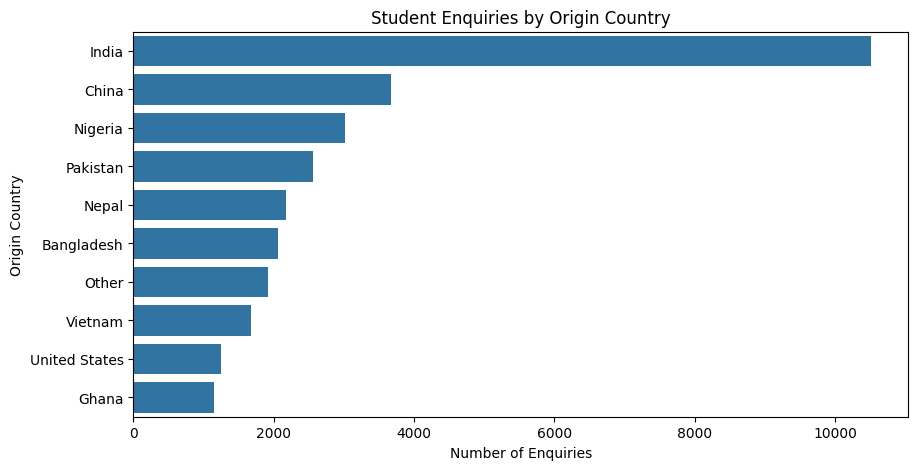

In [24]:
plt.figure(figsize=(10,5))

sns.barplot(x=country_enquiries.values,
            y = country_enquiries.index)

plt.title("Student Enquiries by Origin Country")
plt.xlabel("Number of Enquiries")
plt.ylabel("Origin Country")

plt.show()

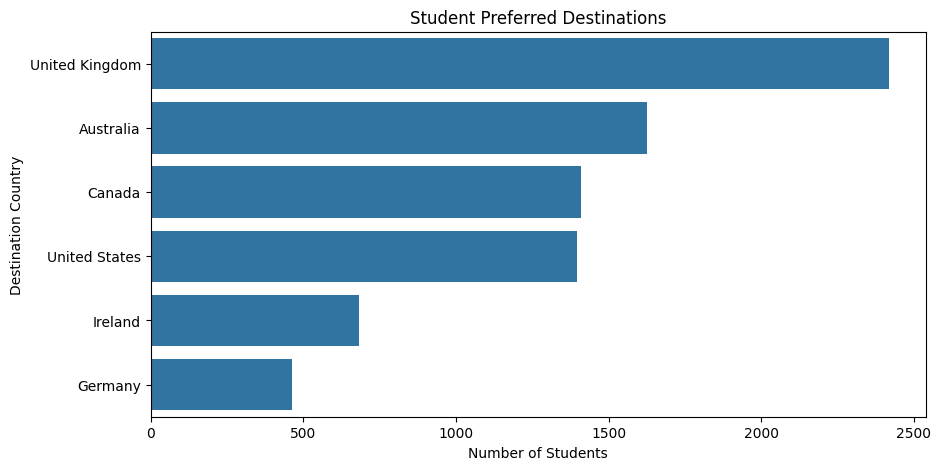

In [25]:
destination_demand = students['preferred_destination_country'].value_counts()

plt.figure(figsize=(10,5))

sns.barplot(x = destination_demand.values,
            y=destination_demand.index)

plt.title("Student Preferred Destinations")
plt.xlabel("Number of Students")
plt.ylabel("Destination Country")

plt.show()


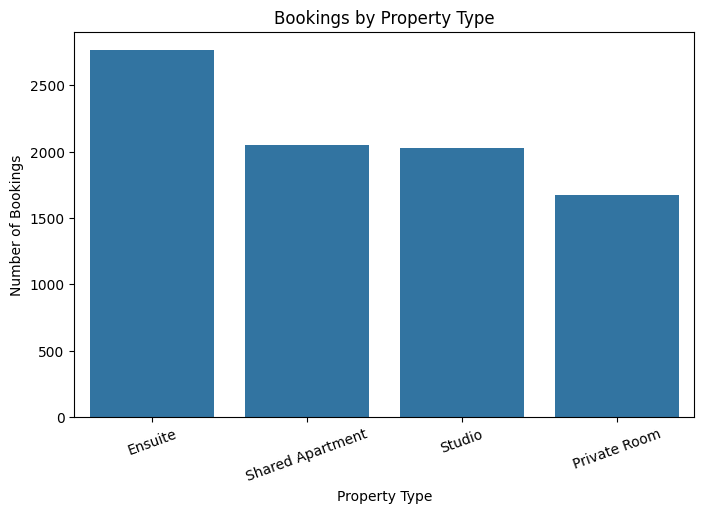

In [26]:
property_demand = bookings.merge(
    properties[["property_id", "property_type"]],
    on="property_id"
)

property_demand = property_demand["property_type"].value_counts()

plt.figure(figsize=(8,5))

sns.barplot(
    x=property_demand.index,
    y=property_demand.values
)

plt.title("Bookings by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=20)

plt.show()

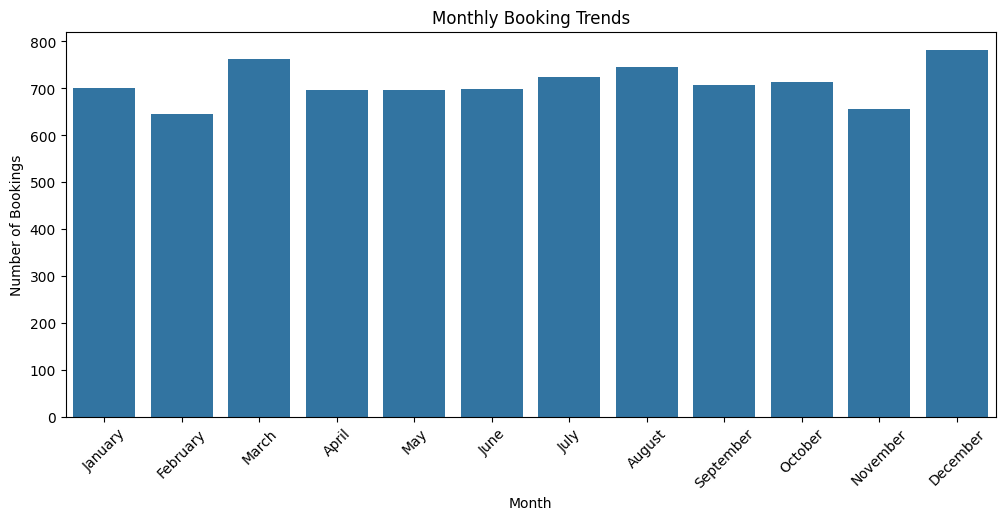

In [27]:
bookings["booking_month"] = bookings['booking_date'].dt.month_name()

monthly_bookings = bookings["booking_month"].value_counts()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_bookings = monthly_bookings.reindex(month_order)

plt.figure(figsize=(12,5))

sns.barplot(
    x=monthly_bookings.index,
    y=monthly_bookings.values
)

plt.title("Monthly Booking Trends")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

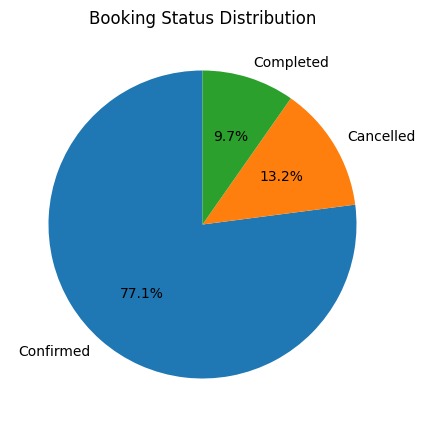

In [28]:
booking_status = bookings['booking_status'].value_counts()

plt.figure(figsize=(7,5))

plt.pie(
    booking_status,
    labels=booking_status.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Booking Status Distribution")

plt.show()

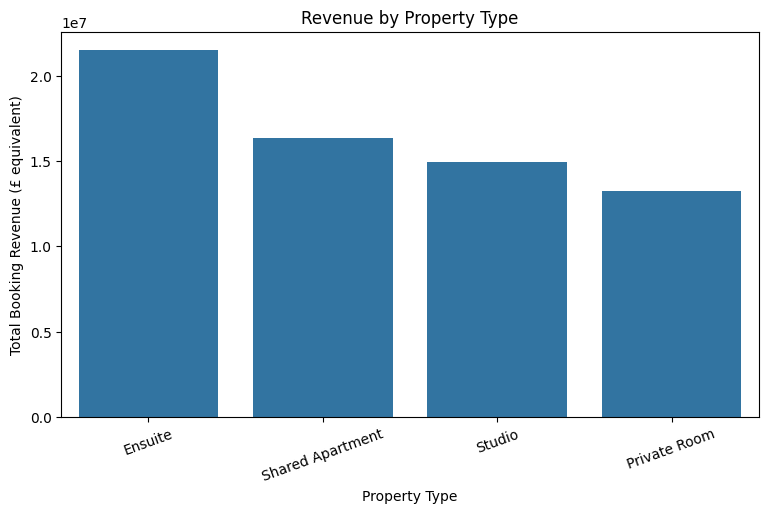

In [29]:
revenue_data = bookings.merge(
    properties[["property_id", "property_type"]],
    on="property_id"
)

revenue_by_type = revenue_data.groupby("property_type")["booking_value_gbp_equivalent"].sum().sort_values(ascending=False)

plt.figure(figsize=(9,5))

sns.barplot(
    x=revenue_by_type.index,
    y=revenue_by_type.values
)

plt.title("Revenue by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Total Booking Revenue (£ equivalent)")
plt.xticks(rotation=20)

plt.show()

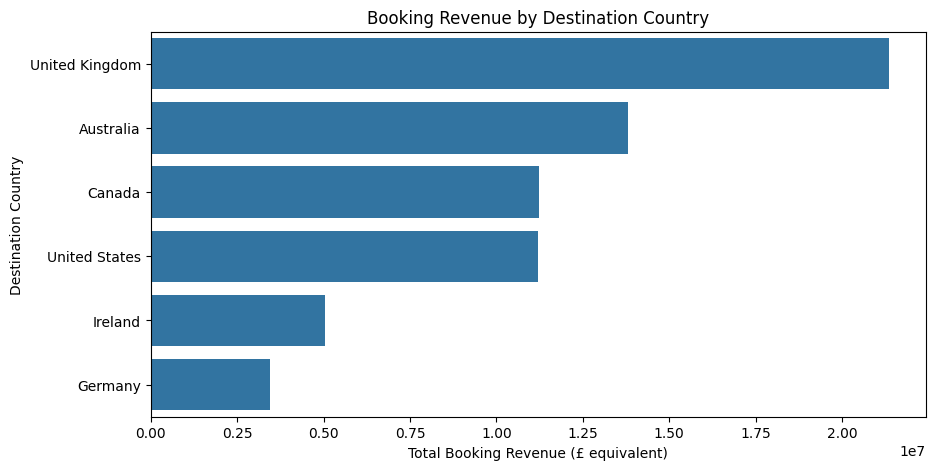

In [30]:
country_revenue = bookings.merge(
    students[["student_id", "preferred_destination_country"]],
    on="student_id"
    )

revenue_by_country = country_revenue.groupby(
    "preferred_destination_country"
)["booking_value_gbp_equivalent"].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))

sns.barplot(
    x=revenue_by_country.values,
    y=revenue_by_country.index
)

plt.title("Booking Revenue by Destination Country")
plt.xlabel("Total Booking Revenue (£ equivalent)")
plt.ylabel("Destination Country")
plt.show()

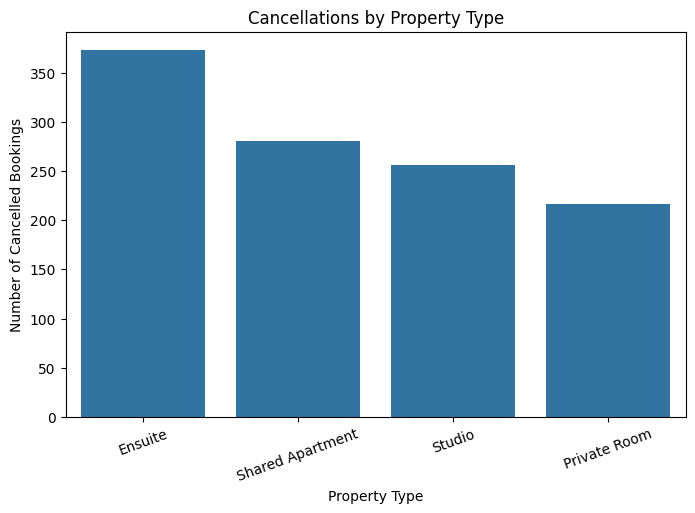

In [31]:
cancellation_data = bookings.merge(
    properties[["property_id", "property_type"]],
    on="property_id"
)

cancellation_data = cancellation_data[
    cancellation_data["booking_status"]=="Cancelled"
]

cancellations = cancellation_data["property_type"].value_counts()

plt.figure(figsize=(8,5))

sns.barplot(
    x=cancellations.index,
    y=cancellations.values
)

plt.title("Cancellations by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Number of Cancelled Bookings")
plt.xticks(rotation=20)
plt.show()

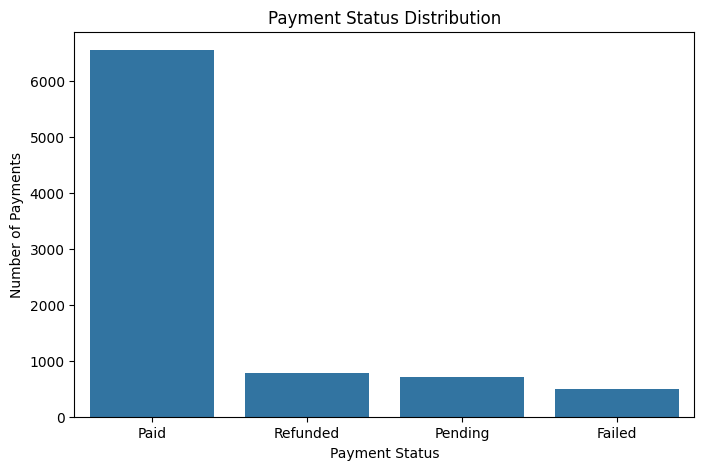

In [32]:
payment_status = payments["payment_status"].value_counts()

plt.figure(figsize=(8,5))

sns.barplot(
    x=payment_status.index,
    y=payment_status.values
)

plt.title("Payment Status Distribution")
plt.xlabel("Payment Status")
plt.ylabel("Number of Payments")
plt.show()

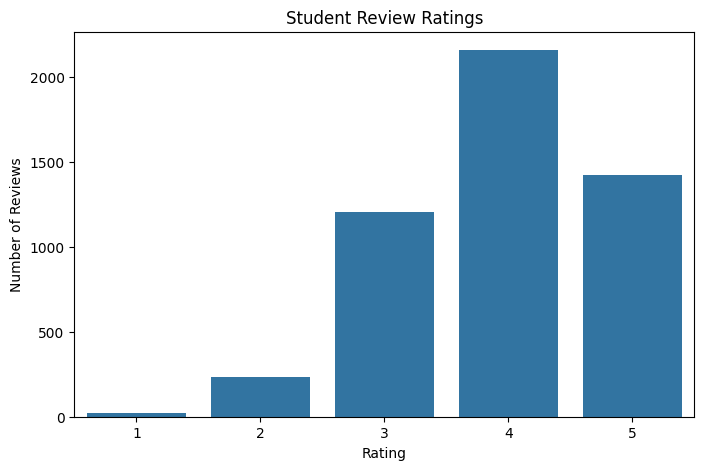

In [36]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews,
    x="overall_rating"
)

plt.title("Student Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

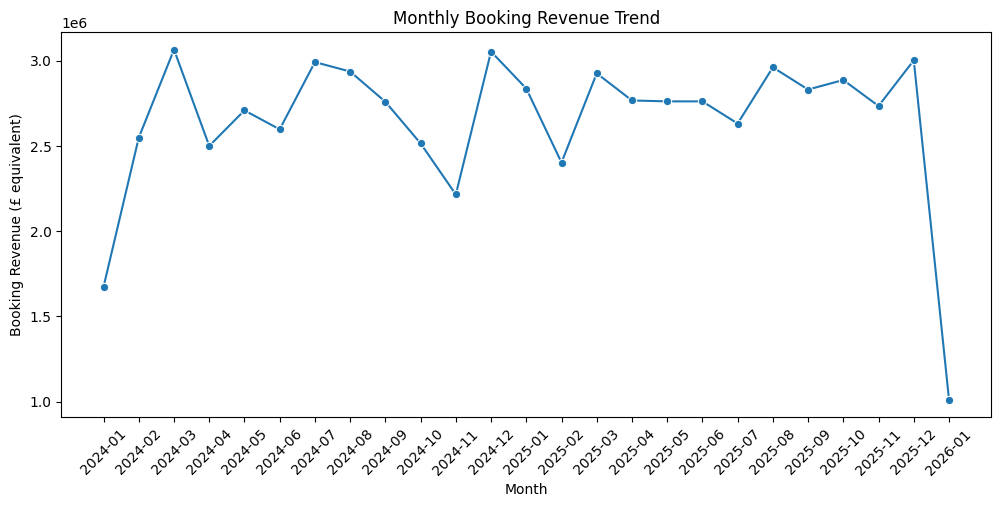

In [37]:
monthly_revenue = bookings.copy()
monthly_revenue["month"] = (
    monthly_revenue["booking_date"].dt.to_period("M")
)

monthly_revenue = monthly_revenue.groupby("month")["booking_value_gbp_equivalent"].sum()

plt.figure(figsize=(12,5))
sns.lineplot(
    x=monthly_revenue.index.astype(str),
    y=monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Booking Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Booking Revenue (£ equivalent)")
plt.xticks(rotation=45)
plt.show()

In [38]:
average_booking_value = bookings['booking_value_gbp_equivalent'].mean()

print("Average Booking Value: £", round(average_booking_value, 2))

Average Booking Value: £ 7749.69


In [39]:
total_enquiries = enquiries['enquiry_id'].nunique()
total_bookings = bookings['booking_id'].nunique()

conversion_rate = (total_bookings/total_enquiries)*100

print("Total Enquiries:", total_enquiries)
print("Total Bookings:", total_bookings)
print("Booking Conversion Rate:", round(conversion_rate, 2), "%")

Total Enquiries: 30000
Total Bookings: 8527
Booking Conversion Rate: 28.42 %
